### STFT


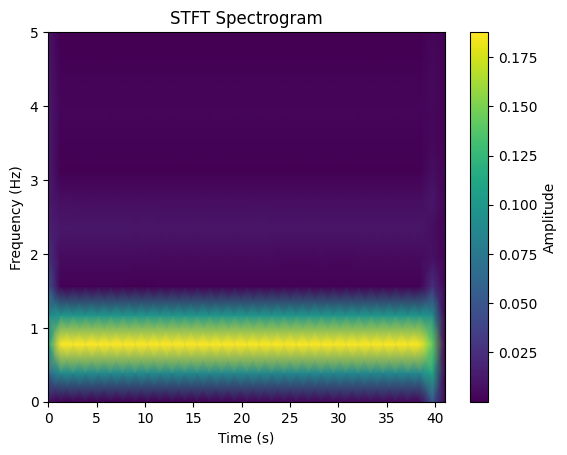

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft

# LAOS t24 column 123 (only stress time, stress, and strain)
df = pd.read_excel("/mnt/c/Users/sylvi/Desktop/test FT.xlsx")

time = df["Step time"].values
stress = df["Stress"].values

stress = stress - np.mean(stress)


dt = time[1] - time[0]
fs = 1 / dt

# STFT
f, t, Zxx = stft(
    stress,
    fs=fs,
    nperseg=128,
    noverlap=64
)


plt.pcolormesh(t, f, np.abs(Zxx), shading='gouraud')
plt.ylabel("Frequency (Hz)")
plt.xlabel("Time (s)")
plt.title("STFT Spectrogram")
plt.colorbar(label="Amplitude")
plt.ylim(0, 5)
plt.show()

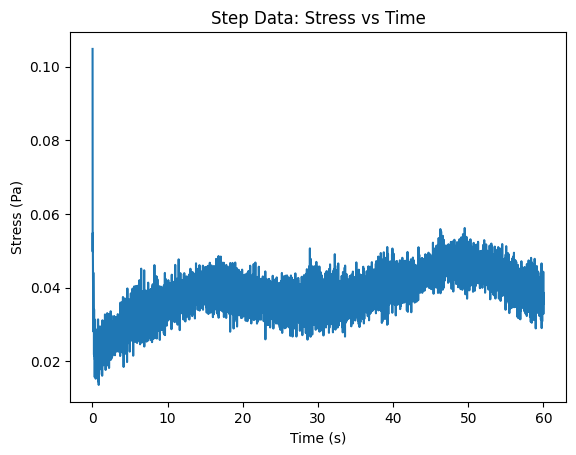

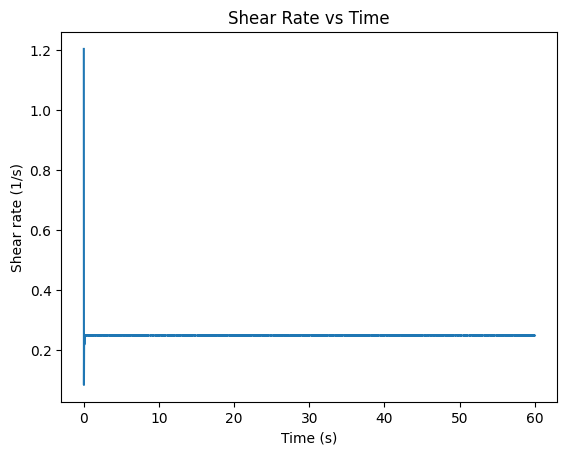

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft

df = pd.read_excel("/mnt/c/Users/sylvi/Desktop/test FT.xlsx")

time = pd.to_numeric(df["Step time"], errors="coerce")
stress = pd.to_numeric(df["Stress"], errors="coerce")
shear_rate = pd.to_numeric(df["Shear rate"], errors="coerce")

mask = time.notna() & stress.notna() & shear_rate.notna()
time = time[mask].to_numpy()
stress = stress[mask].to_numpy()
shear_rate = shear_rate[mask].to_numpy()

# 画原始 stress
plt.plot(time, stress)
plt.xlabel("Time (s)")
plt.ylabel("Stress (Pa)")
plt.title("Step Data: Stress vs Time")
plt.show()

# 画 shear rate，看看 step 在哪里发生
plt.plot(time, shear_rate)
plt.xlabel("Time (s)")
plt.ylabel("Shear rate (1/s)")
plt.title("Shear Rate vs Time")
plt.show()

In [5]:
pip install openpyxl

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]1/2 [openpyxl]

[notice] A new release of pip is available: 25.1.1 -> 26.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### CWT

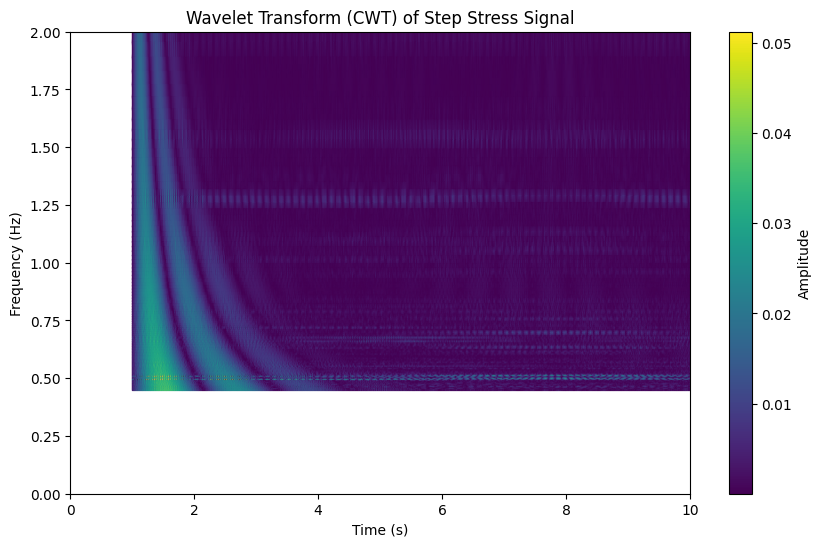

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pywt

# Read file

df = pd.read_excel("/mnt/c/Users/sylvi/Desktop/test FT.xlsx")

time = pd.to_numeric(df["Step time"], errors="coerce")
stress = pd.to_numeric(df["Stress"], errors="coerce")
shear_rate = pd.to_numeric(df["Shear rate"], errors="coerce")

# get rid of the peak at time = 0
mask = time > 1   
time_clean = time[mask]
stress_clean = stress[mask]

# centralisation
stress_clean = stress_clean - np.mean(stress_clean)

# 
dt = np.mean(np.diff(time_clean))

# 
scales = np.arange(1, 128)

# CWT
coeffs, freqs = pywt.cwt(
    stress_clean,
    scales,
    'morl',   # Morlet wavelet
    sampling_period=dt
)


plt.figure(figsize=(10, 6))

plt.pcolormesh(
    time_clean,
    freqs,
    np.abs(coeffs),
    shading='gouraud'
)

plt.ylabel("Frequency (Hz)")
plt.xlabel("Time (s)")
plt.title("Wavelet Transform (CWT) of Step Stress Signal")
plt.colorbar(label="Amplitude")

plt.xlim(0, 10)
plt.ylim(0, 2)   
plt.show()

### Simulation
x(t)=A(t)⋅sin(2πft)+ϵ(t)

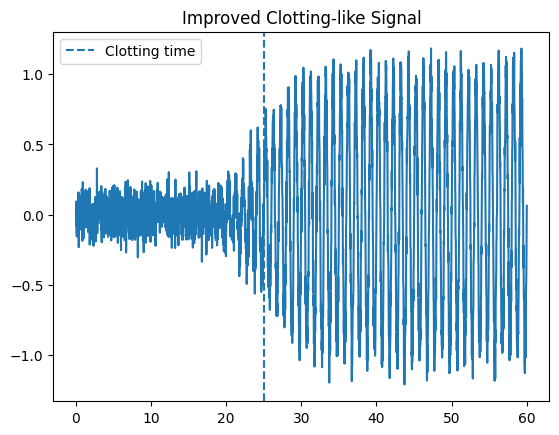

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 60, 3000)

# clotting envelope
t_clot = 25
k = 0.4
A = 1 / (1 + np.exp(-k * (t - t_clot)))

# oscillation
freq = 1  # Hz
signal = A * np.sin(2 * np.pi * freq * t)

# noise
signal += 0.1 * np.random.randn(len(t))

plt.plot(t, signal)
plt.axvline(t_clot, linestyle='--', label="Clotting time")
plt.legend()
plt.title("Improved Clotting-like Signal")
plt.show()

FT --> FFT


X(f)=∫x(t)e−i2πftdt

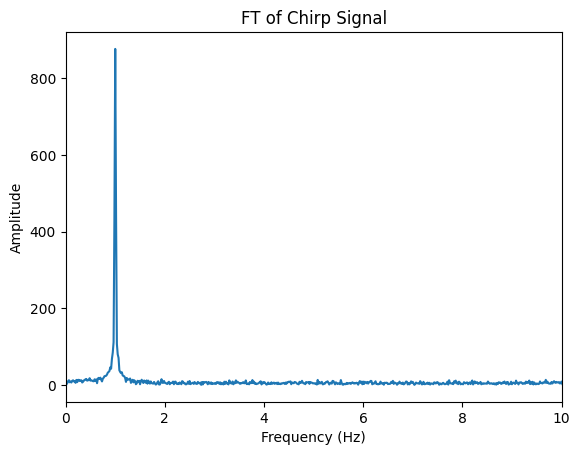

In [18]:
dt = t[1] - t[0]
fft_vals = np.fft.fft(signal - np.mean(signal))
freqs = np.fft.fftfreq(len(signal), d=dt)

pos = freqs > 0
plt.plot(freqs[pos], np.abs(fft_vals[pos]))
plt.xlim(0, 10)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("FT of Chirp Signal")
plt.show()

STFT

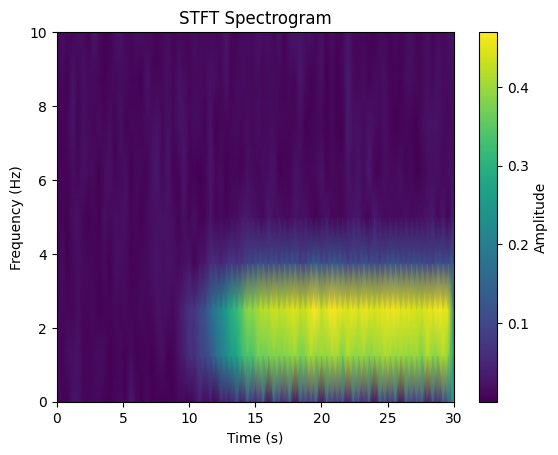

In [23]:
f, tt, Zxx = stft(signal, fs=fs, nperseg=80, noverlap=40)

plt.pcolormesh(tt, f, np.abs(Zxx), shading="gouraud")
plt.ylim(0, 10)
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("STFT Spectrogram")
plt.colorbar(label="Amplitude")
plt.show()

CWT --> Morlet Wavelet

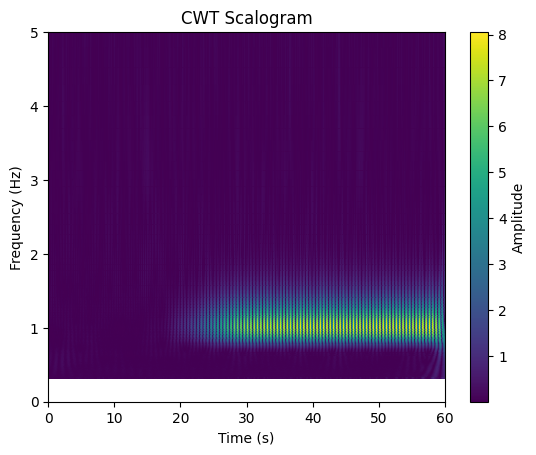

In [24]:
scales = np.arange(1, 128)

coeffs, freqs = pywt.cwt(
    signal,
    scales,
    "morl", # morlet wavelet
    sampling_period=dt
)

plt.pcolormesh(t, freqs, np.abs(coeffs), shading="gouraud")
plt.ylim(0, 5)
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("CWT Scalogram")
plt.colorbar(label="Amplitude")
plt.show()